#### Routing Problem with ACO

Ant Colony Optimization (ACO) is a nature-inspired algorithm for solving hard combinatorial optimization problems—especially routing, sequencing, and assignment problems where evaluating every possible solution is computationally intractable.




##### How the ACO Algorithm Works

In computational ACO, artificial "ants" construct candidate solutions step by step over a graph

- Probabilistic transition rule: At node $i$, an ant chooses the next unvisited node $j$ probabilistically based on both pheromone intensity $\tau_{ij}$ (learned experience) and heuristic desirability $\eta_{ij}$ (problem-specific attractiveness, such as inverse distance $1/d_{ij}$):$$P_{ij}^k = \frac{[\tau_{ij}]^{\alpha} [\eta_{ij}]^{\beta}}{\sum_{l \in \mathcal{N}_i^k} [\tau_{il}]^{\alpha} [\eta_{il}]^{\beta}}$$.

- Pheromone evaporation and update: After ants build tours or solutions, pheromone levels decay across edges to encourage exploration, and stronger reinforcement is added to edges belonging to high-quality (low-cost) solutions:$$\tau_{ij} \leftarrow (1 - \rho)\,\tau_{ij} + \sum_{k=1}^{m} \Delta\tau_{ij}^k$$


##### Applications, Strengths, and Trade-offs

ACO is widely applied to routing and discrete scheduling problems where exact solvers (such as Mixed-Integer Linear Programming) scale poorly on large instances. In FitsLogistics & Routing, typical problems are Traveling Salesperson (TSP), Vehicle Routing (VRP / VRPTW). Why ACO? It naturally builds sequential routes and adapts to dynamic or stochastic travel times.

In [ ]:
!pip install optalgotools > /dev/null

In [ ]:
import osmnx as ox
from optalgotools.routing import cost, draw_route
from optalgotools.structures import Node
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import tqdm
from tqdm import tqdm
import random

Define Search Space

In [ ]:
# NYC
center = (40.766876, -73.979076)
source_point = (40.767686, -73.978591)
destination_point = (40.758815, -73.998772)
reference = (40.766876, -73.979076)

# create the graph
G = ox.graph_from_point(reference, dist=300, simplify=True)

# get the osmid of the nearest nodes to the point
source_id = ox.distance.nearest_nodes(G, source_point[1], source_point[0])
destination_id = ox.distance.nearest_nodes(G, destination_point[1], destination_point[0])

# source and destination nodes
source_node = Node(G, osmid=source_id)
destination_node = Node(G, osmid=destination_id)

highlighted = [destination_node, source_node]

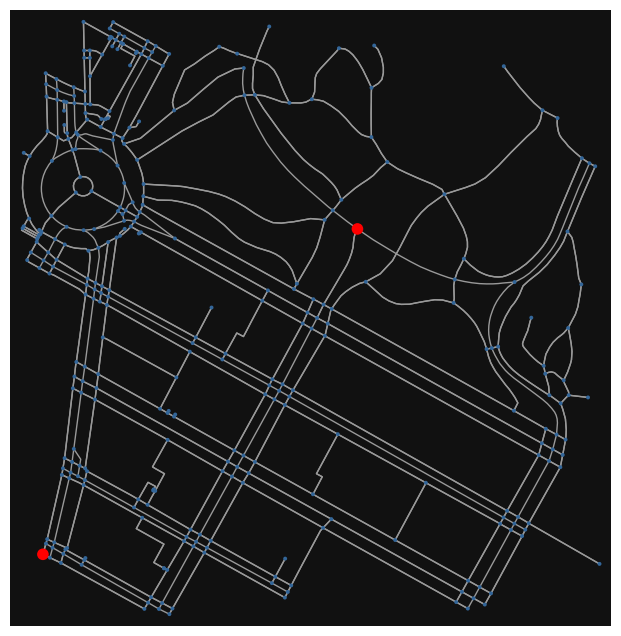

In [ ]:
# mark both source and destination node
nc = ['red' if node in highlighted else '#336699' for node in G.nodes()]
ns = [70 if node in highlighted else 8 for node in G.nodes()]

# plot the graph
fig, ax = ox.plot_graph(G, node_size=ns, node_color=nc, node_zorder=2)

The ANT Colony Algorithm
- Generate n number of ants to fill our population and place them all at the source node (the colony).
- Initialize pheromone concentrations to random values, to seed the graph.
- For each ant
    - The ant examines all the edges leading to neighboring nodes, and probabilistically chooses an edge to travel based on the pheromone levels. If one of the neighboring nodes is the destination, the ant overrides thiz probability and goes straight for the destination.
    - If ant is stuck it retraces its steps back to a previous node with unexplored neighbors.
    - Ant retraces the route and deposits pheromone on the route, eighted inversely to the edge length.
    - If the route is a newly disconnected route, we add it to our list of all known routes.
- The route that is most frequented by the ants is selected as the best solution


In [ ]:
# parameter to control the influence of pheromone
alpha = 1
# parameter to control the influence of desirability in the city
beta = 1
# number of iterations
n = 500
# factor for post-route pheromone increase
Q = 1

pheromone_concentrations = dict()
# randomize
#for node in G.nodes(): pheromone_concentrations[node] = np.random.random()
pheromone_concentrations = {
    (u, v): random.uniform(0, 0.5) for (u, v) in G.edges() }

known_routes = dict()

In [ ]:
# calculate pheromone levels
def pheromone(level, distance, alpha, beta):
    return (level ** alpha) * ((1 / distance) ** beta)

In [ ]:
for ant in tqdm(range(n)):
    # place ant at colony
    frontier = [source_node]
    explored = set()
    route = []
    found = False

    while frontier and not found:
        parent = frontier.pop(0)
        explored.add(parent)

        children = []
        children_pheromone = []
        for child in parent.expand():
            if child == destination_node:
                found = True
                route = child.path()
                continue
            if child not in explored:
                children.append(child)
                children_pheromone.append(
                    pheromone(
                        pheromone_concentrations[(parent.osmid, child.osmid)],
                        child.distance, alpha, beta
                    )
                )
        if len(children) ==0:
            continue

        transition_probability = [
            child_pheromone / sum(children_pheromone) for child_pheromone in children_pheromone
        ]

        # probabilistically choose a child to explore base weighted by transition_probability
        chosen = random.choices(
            children, weights=transition_probability, k=1)[0]

        # all all non explored children in case we have to do that
        children.pop(children.index(chosen))
        frontier.extend(children)

        # set the chosen child to be the next node to explore
        frontier.insert(0, chosen)

    # after completing route increase pheromone levels on that route for the next ant to detect
    for u, v, in zip(route[:-1], route[1:]):
        length_of_edge = G[u][v][0]['length']
        pheromone_concentrations[(u, v)] += Q / length_of_edge

    # if route newly discovered all it to the list
    route = tuple(route)
    if route in known_routes:
        known_routes[route] +=1
    else:
        known_routes[route] =1

Print the best route and its cost and visualize the route

In [ ]:
best_route = max(known_routes, key=known_routes.get)
times_used = known_routes[best_route]

route = list(best_route)
print('cost', cost(G, route))
print('times used', times_used)
#draw_route(G, route)

cost 988.7692
times used 4


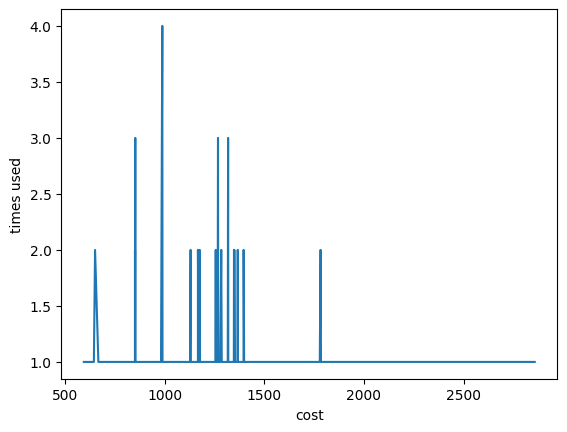

In [ ]:
costs = [cost(G, route) for route in known_routes]
used = list(known_routes.values())

costs, used = zip(*sorted(zip(costs, used)))

plt.plot(costs, used)
plt.xlabel('cost')
plt.ylabel('times used')
plt.show()